# Robustness to nuisance parameters

The Fisher $\sigma_{A_B}$ and $\chi^2_{\min}$ of the bias analysis hold for a fixed geometry and a phase curve without further terms. A real analysis marginalises over the transit geometry and usually fits ellipsoidal terms. Every such nuisance is one more column of the same linear least-squares problem (`simple_bias_analysis`, "Robustness to nuisance parameters"), linearised around the noiseless $A_B$-only fit in whitened units, each column with its mean removed per detector (the free baseline):
$$\delta = \arg\min\ \lVert r_\perp - X\delta\rVert^2 + \sum_\nu (\delta_\nu/\sigma_{p,\nu})^2, \qquad {\rm Cov} = (X^{\sf T}X + \Lambda)^{-1},$$
with $r_\perp$ the residual of the $A_B$-only fit, $X = [j_A, j_{\nu_1}, \dots]$, $j = \partial m_{\rm ps}/\partial\theta/\sigma_{\rm bin}$, and a Gaussian prior on a nuisance as a penalty row (a flat prior adds none). From it: $\sigma_{A_B} = \sqrt{{\rm Cov}_{AA}}$, the shifted fit $\hat A_B + \delta_A$, the new minimum $\chi^{2\prime}_{\min}$, and per nuisance the shrinkage $\sigma_{\rm post}/\sigma_{\rm prior}$ (1: the data add nothing to the prior). If the extended-source model carries the same nuisances with the same priors, $\langle\ln B\rangle \approx \chi^{2\prime}_{\min}/2$ to first order (the determinant terms cancel).

**The columns.**
- **Geometry** $a/R_\star$, $R_p/R_\star$ and the inclination, parametrised as the planet's source fitted them, each with a Gaussian prior from that paper (independent priors, correlations ignored). Taş et al. (2026) fit the impact parameter $b$ of TOI-2431 b and derive $i = \arccos[b/(a/R_\star)]$, so its geometry is $(a/R_\star, R_p/R_\star, b)$, with $a/R_\star$ varied at fixed $b$; Malavolta et al. (2018) fit $i$ of K2-141 b directly. The columns are central differences of the point-source model in $a/R_\star$, $R_p/R_\star$ and $i$; the $b$ column and the $a/R_\star$ column at fixed $b$ follow from them by the chain rule. The transit and the occultation are part of the model (`transit=True`), so their shape constrains the geometry as well; the shrinkage shows by how much.
- **Stellar ellipsoidal variation**: the planet stretches the star, $-\cos 4\pi\phi$ in ppm, in every bin including the occultation (the star stays visible). Two forms. *Physical* (`stellar_shared`): the relative amplitude $A_{\rm ell} = \alpha_{\rm ell}(M_p/M_\star)(R_\star/a)^3\sin^2 i$ depends on the band only through $\alpha_{\rm ell}(u, g)$, by less than about 10 % across these bands, so one amplitude serves all detectors (band ratios `STELLAR_RATIOS`, achromatic by default), with a Gaussian prior from the published mass ratio and geometry (section 3). *Free per band* (`stellar`): one amplitude per detector, flat prior. This is the worst case, an analysis that fits ellipsoidal variations without physical constraint; it can follow the wavelength dependence of whatever it absorbs.
- **Planetary tidal deformation**, as in Akinsanmi et al. (2024): the planet's flux times its projected area relative to mid-transit, $F_p(\phi)\,A(\phi)/A(0)$, with $A(\phi)$ the projected area of a triaxial ellipsoid (Leconte et al. 2011) of the Correia (2014) shape $r_1 = r_2(1+3q)$, $r_3 = r_2(1-q)$ ($r_1$ towards the star, $r_2$ along the orbit, $r_3$ polar). The amplitude is $\delta = (r_1 - r_2)/r_2 = 3q$, and the column is the derivative at $\delta = 0$, $F_p(\phi)\sin^2 i\,\sin^2 2\pi\phi$, with $F_p$ the point-source planet flux at the fitted $A_B$; one amplitude shared by all detectors (it is geometric), flat prior. It vanishes during the occultation, like the difference between the two irradiation models.

Sections 1–4 treat the $A_B$-only fit: the fit with redistribution sits at the $F = 0$ edge of that fit, where nothing linear in $F$ is trustworthy. Section 5 linearises it around its own solution instead and gives both fits with the same nuisances; section 6 scans the free-geometry row over the prior widths and the observing time, and section 7 adds the stellar $T_{\rm eff}$, a prior on the planetary deformation and a binning check.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
from simple_bias_analysis import *
from HItargets_utils import *

set_plot_style()

In [2]:
# Baseline settings (HItargets_utils.py)
A_B_true = DEFAULT_A_B
A_model = ConstantBandAlbedo(DEFAULT_A)
u, u_bol = DEFAULT_U, DEFAULT_U_BOL
n_orbits, n_bins = DEFAULT_N_ORBITS, DEFAULT_N_BINS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# Planets and modes: MIRI/LRS, the joint NIRSpec fit, and all three detectors jointly (a tuple = one joint fit: shared A_B, a baseline per detector)
LRS, NRS1, NRS2 = "MIRI/LRS", *JWST_BANDS[:2]
MODES = {"joint NIRSpec": (NRS1, NRS2), "MIRI/LRS": LRS, "NIRSpec + LRS": (NRS1, NRS2, LRS)}   # wavelength order (tables, figure lines, figure columns)
PLANETS = ("TOI-2431 b", "K2-141 b")

# The published uncertainties of the reference planets are defined once, with their sources, in HItargets_utils.py: GEOMETRY_SIGMA (Gaussian priors, 1 sigma, on the parameters each source
# FITTED, centred on the adopted values; independent, correlations ignored), GEOMETRY_PARAMS (that parametrisation: (a/R*, Rp/R*, b) for TOI-2431 b, whose source fitted b and derived i;
# (a/R*, Rp/R*, i) for K2-141 b), PLANET_MASSES and the (u, g) bracket of the stellar ellipsoidal term. They are exactly the priors of the free-geometry dynesty runs
# (the free-geometry runs of retrievals/paper_runs/make_runs.py), so the "+ all geometry" row is the prediction for those runs.
PRIORS = {name: dict(GEOMETRY_SIGMA[name]) for name in PLANETS}       # a copy per planet: the prior of the shared stellar amplitude is added to it below
INCLINATION = {name: GEOMETRY_PARAMS[name][2] for name in PLANETS}   # the third geometry parameter, as the planet's source fitted it ("b" or "incl")

# The stellar ellipsoidal term (section 3). Its relative amplitude A_ell = alpha_ell (M_p / M_star) (R_star / a)^3 sin^2 i is set by measured quantities and depends on the band only
# through alpha_ell(u, g), so the realistic nuisance is ONE amplitude for all bands ("stellar_shared") with the prior these imply; one free amplitude per band ("stellar") is the worst case.
MASSES = PLANET_MASSES                                        # M_p [M_E] and its 1 sigma, M_star [M_sun] and its 1 sigma
U_RANGE, G_RANGE = ELLIPSOIDAL_U_RANGE, ELLIPSOIDAL_G_RANGE   # bracket of the linear limb-darkening and gravity-darkening coefficients in the infrared (not tabulated values, see section 3)
STELLAR_RATIOS = None   # alpha_ell of each band relative to the others, {band: ratio}; None = achromatic. Physically within ~10 % across these bands (section 3 varies it by +-15 %)

def mass_ratio(name):
    """M_p / M_star of a planet and its fractional 1-sigma error."""
    Mp, sMp, Ms, sMs = MASSES[name]
    return Mp * M_EARTH_SUN / Ms, float(np.hypot(sMp / Mp, sMs / Ms))

ELLIPSOIDAL = {name: ellipsoidal_prior(hi_planets_by_name(name), *mass_ratio(name), U_RANGE, G_RANGE, sig_a_rs=PRIORS[name]["a_rs"], sig_incl=PRIORS[name]["incl"]) for name in PLANETS}
for name in PLANETS: PRIORS[name]["stellar_shared"] = ELLIPSOIDAL[name]["sigma"]   # [ppm] the prior of the shared amplitude, centred on the truth (which has no ellipsoidal term)

# Rows of the table, per planet: which nuisances are free in addition to A_B and the baseline(s). The geometry follows the source's parametrisation: with b (TOI-2431 b), a/R*
# varies at fixed b ("a_rs|b", i follows); with i (K2-141 b), at fixed i. The single-parameter and single-term rows are diagnostics (tables only); FIGURE_ROWS are the headline rows.
GEOM = ("a_rs", "rp_rs", "incl")   # the finite-difference columns; b and a_rs|b follow from them by the chain rule (nuisance_problem)

def rows_of(name):
    third = INCLINATION[name]
    geom = ("a_rs|b" if third == "b" else "a_rs", "rp_rs", third)
    return {"fixed": (), "+ a/R*": geom[:1], "+ Rp/R*": ("rp_rs",), "+ b or i": (third,), "+ all geometry": geom,
            "+ stellar (physical)": ("stellar_shared",), "+ geometry + stellar (physical)": (*geom, "stellar_shared"), "+ stellar (free per band)": ("stellar",),
            "+ planetary": ("planetary",), "+ geometry + planetary": (*geom, "planetary")}

ROWS = {name: rows_of(name) for name in PLANETS}
FIGURE_ROWS = ["fixed", "+ all geometry", "+ geometry + stellar (physical)", "+ stellar (free per band)", "+ geometry + planetary"]   # the headline rows (figure)
FIGURE_MODES = ["joint NIRSpec", "MIRI/LRS"]   # the paper's primary modes (figure); NIRSpec + LRS is in the tables

# Template cfg: band, planet and noise are replaced per case (retrieval_cfg)
l1, l2 = filter_lambda(LRS)
cfg = FittingConfig(planet=hi_planets_by_name(PLANETS[0]), filter_path=filter_loc(LRS), l1=l1, l2=l2, A_=A_model, sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u)

## 1. The table

One linear problem per planet and mode (`nuisance_problem`: the noiseless truth, the $A_B$-only fit and every column), solved for each row of `ROWS` (`nuisance_table`; all numbers in `TABLES` and the tidy `tab`). Two tables per planet. The first gives per mode $\sigma_{A_B}$, the bias $\Delta A_B$ of the shifted fit, its significance $|\Delta A_B|/\sigma_{A_B}$ and $\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$. The second shows what the nuisances of each row do: for a geometry parameter the shift of its fitted value in units of its posterior $\sigma$ and, in brackets, $\sigma_{\rm post}/\sigma_{\rm prior}$ (1: the data add nothing to the prior); for an ellipsoidal amplitude the fitted value $\pm\,\sigma$ (stellar in ppm, per detector or shared, with its shrinkage where it has the physical prior; planetary as $\delta = (r_1 - r_2)/r_2$). The truth has no ellipsoidal term, so a fitted amplitude is what the point-source model attributes to one.

What to look for:
- **Geometry.** How much $\sigma_{A_B}$ grows and the significance $|\Delta A_B|/\sigma_{A_B}$ drops once the geometry is marginalised, and which parameter does it: $R_p/R_\star$ scales the planet's flux like $A_B$ does, and $a/R_\star$ enters the energy balance through $(1-A_B)(R_\star/a)^2$. A shrinkage well below 1 means the phase curve itself (transit and occultation shape) measures the parameter better than the prior; a shift well below $1\sigma$ means the misspecified model does not bias the geometry noticeably. $\chi^{2\prime}_{\min}$, i.e. the evidence, should hardly move: the residual of the fit is not a geometry-like pattern.
- **How the inclination is treated.** `+ all geometry` uses the source's parametrisation ($b$ for TOI-2431 b, $i$ for K2-141 b) and is the prediction for the free-geometry dynesty runs. Two alternatives are left out of the table: independent $a/R_\star$ and $i$ priors give a $\sigma_{A_B}$ smaller by 1–4 %, and holding $i$ fixed pins $a/R_\star$ and understates $\sigma_{A_B}$ by 5–19 %, depending on the mode (both TOI-2431 b, $A_B$ = 0.2, 5 orbits). For TOI-2431 b, `+ a/R*` holds $b$ fixed.
- **Diagnostic rows.** The single-parameter rows (`+ a/R*`, `+ Rp/R*`, `+ b or i`) show which parameter drives the change, and the rows without geometry (`+ stellar (physical)`, `+ planetary`) isolate each term. The headline rows are those of the figure (`FIGURE_ROWS`).
- **Ellipsoidal terms.** Both have the $-\cos 4\pi\phi$ shape of the residual. Compare the physical stellar rows with the free ones: how much of $\chi^2_{\min}$ each absorbs, the amplitude it takes (the physical one against its prior, `shrink stellar_shared`; the free one against the expected amplitude of section 3), and what it does to the bias. The planetary term is nearly a rescaling of the planet's flux between quadrature and conjunction and therefore degenerate with $A_B$.

In [3]:
def case(name, mode):
    '''The nuisance problem of one planet in one mode: its own geometry and noise, the noiseless hyperillumination truth, every column.'''
    pl = hi_planets_by_name(name)
    c = retrieval_cfg(cfg, pl, MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, **kw)

CASES = [(name, mode) for name in PLANETS for mode in MODES]
PROBLEMS = dict(zip(CASES, pmap(case, CASES)))
TABLES = {k: nuisance_table(p, A_B_true, ROWS[k[0]]) for k, p in PROBLEMS.items()}
tab = pd.concat([t.assign(planet=k[0], mode=k[1]) for k, t in TABLES.items()], ignore_index=True)   # tidy: one row per planet, mode and nuisance row

# Display, per planet: the four key numbers per mode (one column group per mode), then what the nuisances of each row do
HEAD = {"sigma_A_B": "σ_AB", "bias_A_B": "ΔA_B", "bias_sigma": "|ΔA_B|/σ", "lnB_mean": "⟨ln B⟩"}
SHORT = {"a_rs": "a/R*", "a_rs|b": "a/R*", "rp_rs": "Rp/R*", "b": "b", "incl": "i", "planetary": "planetary"}

def nuisance_text(p, nuisances, mode):
    '''The nuisances of one row in one line: the shift of each geometry parameter in posterior sigma and its sigma_post / sigma_prior, the fitted value +- sigma of each ellipsoidal amplitude.'''
    s, dets = nuisance_solve(p, nuisances), [detector_label(d) for d in detectors(MODES[mode])]
    parts = []
    for n in s["names"]:
        v, e, sh = s["delta"][n], s["sigma_post"][n], s["shrinkage"][n]
        if n in p["values"]: parts.append(f"{SHORT[n]} {v / e:+.2f}σ ({sh:.2f})")   # shift in posterior sigma (sigma_post / sigma_prior)
        elif n.startswith("stellar:"): parts.append(f"stellar {dets[int(n.split(':')[1]) - 1]} {v:.1f} ± {e:.1f} ppm")
        elif n == "stellar_shared": parts.append(f"stellar {v:.1f} ± {e:.1f} ppm (shrink {sh:.2f})")
        else: parts.append(f"{SHORT[n]} {v:.3f} ± {e:.3f}")
    return " · ".join(parts) or "-"

for name in PLANETS:
    summary = pd.concat({mode: TABLES[(name, mode)].set_index("row")[list(HEAD)].rename(columns=HEAD) for mode in MODES}, axis=1)
    summary.index.name = None
    fits = ", ".join(f"{m} {PROBLEMS[(name, m)]['A_B_fit']:.3f}" for m in MODES)
    display(summary.style.format("{:.3g}").set_caption(f"{name}: σ_AB, bias ΔA_B, |ΔA_B|/σ_AB and ⟨ln B⟩ = χ²′_min / 2 per row (A_B,fit without nuisances: {fits})"))
    details = pd.DataFrame({mode: {label: nuisance_text(PROBLEMS[(name, mode)], nuis, mode) for label, nuis in ROWS[name].items()} for mode in MODES})
    display(details.style.set_caption(f"{name}: the nuisances of each row (geometry: shift of the fitted value in posterior σ, σ_post / σ_prior in brackets; amplitudes: fitted value ± σ)").set_properties(**{"text-align": "left"}))

,joint NIRSpec,MIRI/LRS,NIRSpec + LRS
fixed,-,-,-
+ a/R*,a/R* -0.58σ (0.16),a/R* -0.68σ (0.30),a/R* -0.84σ (0.14)
+ Rp/R*,Rp/R* +0.41σ (0.18),Rp/R* +0.23σ (0.36),Rp/R* +0.49σ (0.17)
+ b or i,b -0.53σ (0.14),b -0.58σ (0.26),b -0.74σ (0.12)
+ all geometry,a/R* -0.38σ (0.74) · Rp/R* +0.25σ (0.22) · b +0.28σ (0.68),a/R* -0.36σ (0.75) · Rp/R* -0.03σ (0.41) · b +0.10σ (0.69),a/R* -0.64σ (0.73) · Rp/R* +0.30σ (0.20) · b +0.50σ (0.67)
+ stellar (physical),stellar 1.3 ± 0.7 ppm (shrink 0.80),stellar 0.9 ± 0.9 ppm (shrink 0.94),stellar 1.8 ± 0.7 ppm (shrink 0.77)
+ geometry + stellar (physical),a/R* -0.28σ (0.74) · Rp/R* -0.01σ (0.23) · b +0.22σ (0.68) · stellar 1.3 ± 0.8 ppm (shrink 0.83),a/R* -0.33σ (0.75) · Rp/R* -0.10σ (0.41) · b +0.10σ (0.69) · stellar 0.9 ± 0.9 ppm (shrink 0.95),a/R* -0.46σ (0.74) · Rp/R* -0.10σ (0.21) · b +0.39σ (0.67) · stellar 1.8 ± 0.7 ppm (shrink 0.80)
+ stellar (free per band),stellar NRS1 3.0 ± 1.5 ppm · stellar NRS2 4.6 ± 1.8 ppm,stellar LRS 7.8 ± 2.5 ppm,stellar NRS1 3.1 ± 1.5 ppm · stellar NRS2 4.7 ± 1.8 ppm · stellar LRS 7.3 ± 2.3 ppm
+ planetary,planetary 0.099 ± 0.047,planetary 0.145 ± 0.067,planetary 0.112 ± 0.038
+ geometry + planetary,a/R* -0.20σ (0.74) · Rp/R* +0.27σ (0.22) · b +0.24σ (0.68) · planetary 0.100 ± 0.049,a/R* -0.13σ (0.76) · Rp/R* +0.07σ (0.41) · b +0.21σ (0.69) · planetary 0.149 ± 0.072,a/R* -0.37σ (0.74) · Rp/R* +0.31σ (0.20) · b +0.42σ (0.67) · planetary 0.112 ± 0.039


,joint NIRSpec,MIRI/LRS,NIRSpec + LRS
fixed,-,-,-
+ a/R*,a/R* -0.44σ (0.16),a/R* -0.43σ (0.34),a/R* -0.58σ (0.15)
+ Rp/R*,Rp/R* +0.47σ (0.16),Rp/R* +0.29σ (0.35),Rp/R* +0.55σ (0.14)
+ b or i,i +0.41σ (0.24),i +0.36σ (0.50),i +0.53σ (0.22)
+ all geometry,a/R* -0.19σ (0.54) · Rp/R* +0.30σ (0.19) · i -0.11σ (0.85),a/R* -0.22σ (0.60) · Rp/R* +0.11σ (0.40) · i -0.01σ (0.87),a/R* -0.28σ (0.54) · Rp/R* +0.33σ (0.17) · i -0.18σ (0.85)
+ stellar (physical),stellar 0.2 ± 0.4 ppm (shrink 0.97),stellar 0.1 ± 0.4 ppm (shrink 1.00),stellar 0.2 ± 0.4 ppm (shrink 0.97)
+ geometry + stellar (physical),a/R* -0.18σ (0.54) · Rp/R* +0.27σ (0.19) · i -0.11σ (0.85) · stellar 0.2 ± 0.4 ppm (shrink 0.98),a/R* -0.22σ (0.60) · Rp/R* +0.10σ (0.40) · i -0.01σ (0.87) · stellar 0.1 ± 0.4 ppm (shrink 1.00),a/R* -0.27σ (0.54) · Rp/R* +0.29σ (0.17) · i -0.17σ (0.85) · stellar 0.2 ± 0.4 ppm (shrink 0.97)
+ stellar (free per band),stellar NRS1 2.6 ± 1.8 ppm · stellar NRS2 4.0 ± 2.3 ppm,stellar LRS 6.7 ± 3.6 ppm,stellar NRS1 2.6 ± 1.8 ppm · stellar NRS2 4.0 ± 2.3 ppm · stellar LRS 6.3 ± 3.2 ppm
+ planetary,planetary 0.091 ± 0.062,planetary 0.134 ± 0.103,planetary 0.101 ± 0.052
+ geometry + planetary,a/R* -0.04σ (0.54) · Rp/R* +0.35σ (0.19) · i -0.09σ (0.85) · planetary 0.091 ± 0.065,a/R* -0.01σ (0.60) · Rp/R* +0.18σ (0.40) · i -0.06σ (0.87) · planetary 0.134 ± 0.108,a/R* -0.09σ (0.54) · Rp/R* +0.40σ (0.17) · i -0.14σ (0.85) · planetary 0.100 ± 0.054


**Figure.** The headline rows (`FIGURE_ROWS`) in the two primary modes (`FIGURE_MODES`), as a dot plot: the significance of the albedo bias and the expected evidence side by side for each planet, one line per row, the modes as markers on the same line, and one x scale per quantity for both planets. The diagnostic rows and the three-detector fit are in the tables. The dashed lines mark $1\sigma$ and the evidence thresholds 2.5 and 5.

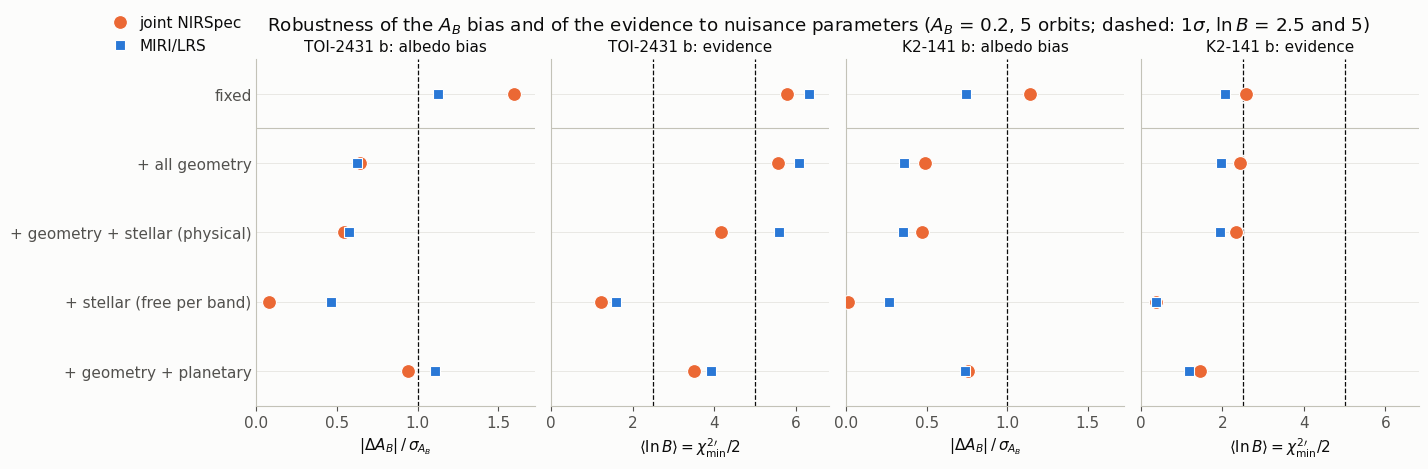

In [4]:
# Horizontal dot plot of the headline rows (FIGURE_ROWS) in the primary modes (FIGURE_MODES): one line per row, the modes as markers on the same line, so a row reads left to right
ypos = {r: k for k, r in enumerate(FIGURE_ROWS)}
METRICS = (("bias_sigma", r"$|\Delta A_B|\,/\,\sigma_{A_B}$", "albedo bias", (1.,)), ("lnB_mean", r"$\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$", "evidence", (2.5, 5.)))
STYLE = dict(zip(MODES, zip((C_HI, C_REDIST, INK_2), "osD", (10, 6.5, 6.5))))   # colour, marker, size: the square fits inside the circle, so coinciding points stay visible
xmax = {col: 1.08 * max(TABLES[(name, m)].set_index("row").loc[FIGURE_ROWS, col].max() for name in PLANETS for m in FIGURE_MODES) for col, *_ in METRICS}   # one x scale per quantity

fig, axs = plt.subplots(1, 2 * len(PLANETS), figsize=(15., 0.5 * len(FIGURE_ROWS) + 2.), sharey=True, gridspec_kw=dict(wspace=0.06))
for j, name in enumerate(PLANETS):
    for m, (col, xlabel, what, refs) in enumerate(METRICS):
        ax = axs[2 * j + m]
        ax.grid(False)
        for yy in ypos.values(): ax.axhline(yy, color="#e6e5e0", lw=0.6, zorder=0)    # one guide line per row
        ax.axhline(0.5, color=AXIS, lw=0.8, zorder=0)                                  # the reference row apart from the rest
        for v in refs: ax.axvline(v, color=INK, lw=0.9, ls="--", zorder=1)
        for mode in FIGURE_MODES:
            c, mk, ms = STYLE[mode]
            t = TABLES[(name, mode)].set_index("row")
            ax.plot([t.loc[r, col] for r in FIGURE_ROWS], list(ypos.values()), mk, ls="none", color=c, ms=ms, mec="white", mew=0.8, zorder=3, label=mode)
        ax.set_xlim(0., xmax[col]); ax.set_xlabel(xlabel); ax.set_title(f"{name}: {what}", fontsize=11)
axs[0].set_ylim(len(FIGURE_ROWS) - 0.5, -0.5)
axs[0].set_yticks(list(ypos.values()), FIGURE_ROWS)
for ax in axs: ax.tick_params(axis="y", length=0)   # the rows are labelled on the left only
axs[0].legend(loc="lower right", bbox_to_anchor=(-0.03, 1.), borderaxespad=0., handletextpad=0.3)   # above the row labels, where it stays clear of the data
fig.suptitle(rf"Robustness of the $A_B$ bias and of the evidence to nuisance parameters ($A_B$ = {A_B_true:g}, {n_orbits} orbits; dashed: $1\sigma$, $\ln B$ = 2.5 and 5)")
fig.tight_layout(rect=(0., 0., 1., 0.95))
plt.show()

## 2. Why the ellipsoidal terms absorb the evidence

The whitened residual of the point-source model before and after the $A_B$ fit, against the ellipsoidal terms, each fitted alone (with $A_B$ and the baseline): the stellar term with the physical prior and the planetary term as in the table, and, faint, the stellar term free per band (the worst case, still a headline row). Before the fit, $r_0$ is the residual at the true $A_B$; after it, $r_\perp$ is that of the $A_B$-only fit. To first order $r_0 = \Delta A_B\, j_A + r_\perp$ with $r_\perp \perp j_A$, so $|r_0|^2 = (\Delta A_B/\sigma_{A_B})^2 + \chi^2_{\min}$: the albedo-like part of the hyperillumination signature becomes the bias, the rest the evidence (both printed per case).

Two figures per planet. The first shows each column at its fitted amplitude, $a\,c$. A fitted column is $a\,c = r_0 - \Delta A_B'\, j_A - r_{\rm fit}$, with $\Delta A_B'$ the bias of its row in section 1 and $r_{\rm fit}$ what the fit leaves: where that bias is close to zero, compare the column with $r_0$, not with $r_\perp$. The second shows what each fit removes from $r_\perp$, $a\,c + \delta_A j_A$ (the column and the readjustment of $A_B$), so the gap to $r_\perp$ is $r_{\rm fit}$. Its sum of squares is $\chi^{2\prime}_{\min}$, for the physical stellar term plus its prior penalty; the printed $\chi^{2\prime}_{\min}/\chi^2_{\min}$ is the share that remains.

The cosines between the vectors are printed. $\cos^2(r_\perp, c)$ is the share of $\chi^2_{\min}$ that a column $c$ takes before $A_B$ readjusts; with $A_B$ free and a flat prior on the amplitude it takes $\cos^2(r_\perp, c)/[1 - \cos^2(j_A, c)]$, larger the more $c$ is degenerate with the albedo response $j_A$. A Gaussian prior multiplies this share by $1 - s^2$, with $s = \sigma_{\rm post}/\sigma_{\rm prior}$ the shrinkage of section 1.

What to look for: the in-occultation level of $r_\perp$. Both irradiation models are zero there, so it is only the fitted baseline, and it has the sign of $-\cos 4\pi\phi$ at $\phi = 0.5$. The stellar term, present during the occultation, therefore matches the residual there as well. The planetary term is zero inside the occultation (in the figure a constant, since every column has its mean removed like the residual) and overlaps with the albedo response outside it. The gap between $r_0$ and $r_\perp$ is the albedo-like part, i.e. the bias; it is small where the bias is small against $\sigma_{A_B}$. In the first figure the physical stellar curve has the shape of the free one at the amplitude its prior allows; in the second, compare how far each curve stays from $r_\perp$.

TOI-2431 b, joint NIRSpec: cos(r_perp, stellar) = +0.77, cos(r_perp, planetary) = +0.34, cos(stellar, planetary) = +0.76, cos(j_A, stellar) = -0.45, cos(j_A, planetary) = -0.84
   |r_0|^2 = 14.22 = chi2_min 11.58 + albedo-like part 2.64 (linear: (dA_B |j_A|)^2 = 2.56);  cos(r_0, j_A) = -0.43, cos(r_0, stellar) = +0.89, cos(r_0, planetary) = +0.67
   chi2'_min / chi2_min (what remains, prior penalty included): stellar ellipsoidal, physical prior 0.73, stellar ellipsoidal, free per band 0.21, planetary deformation 0.61
TOI-2431 b, MIRI/LRS: cos(r_perp, stellar) = +0.76, cos(r_perp, planetary) = +0.33, cos(stellar, planetary) = +0.78, cos(j_A, stellar) = -0.47, cos(j_A, planetary) = -0.84
   |r_0|^2 = 13.97 = chi2_min 12.64 + albedo-like part 1.33 (linear: (dA_B |j_A|)^2 = 1.27);  cos(r_0, j_A) = -0.31, cos(r_0, stellar) = +0.87, cos(r_0, planetary) = +0.58
   chi2'_min / chi2_min (what remains, prior penalty included): stellar ellipsoidal, physical prior 0.91, stellar ellipsoidal, free p

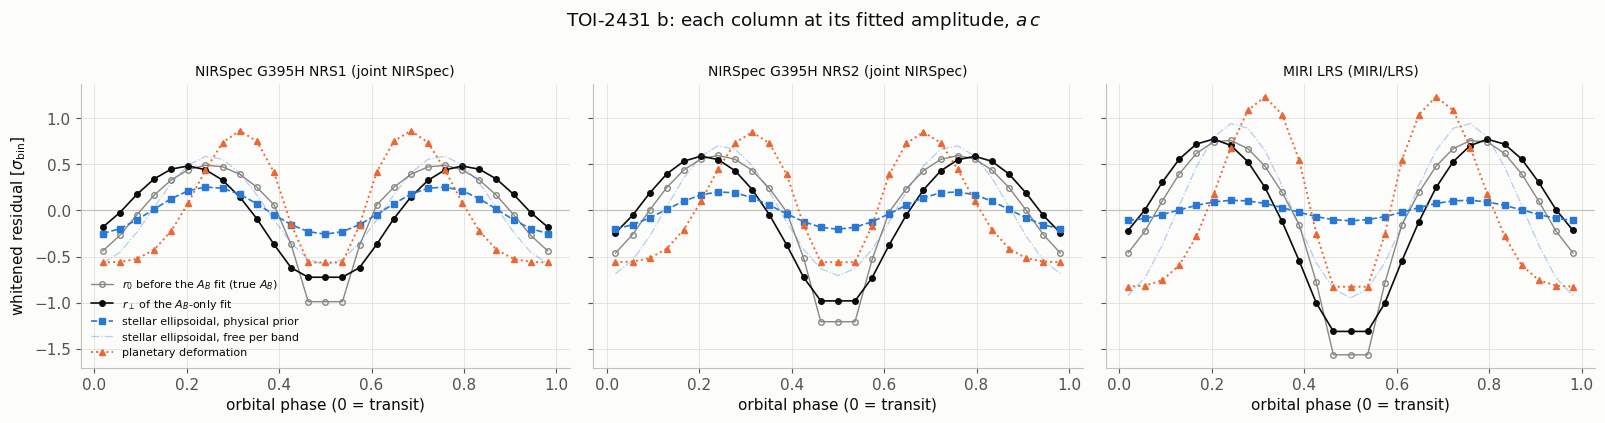

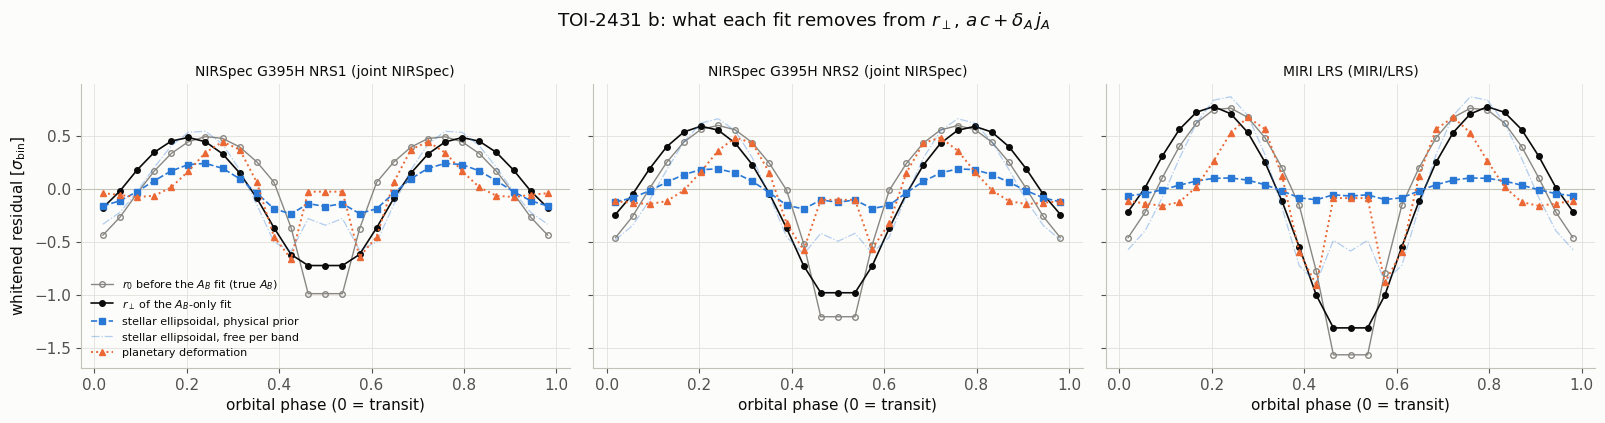

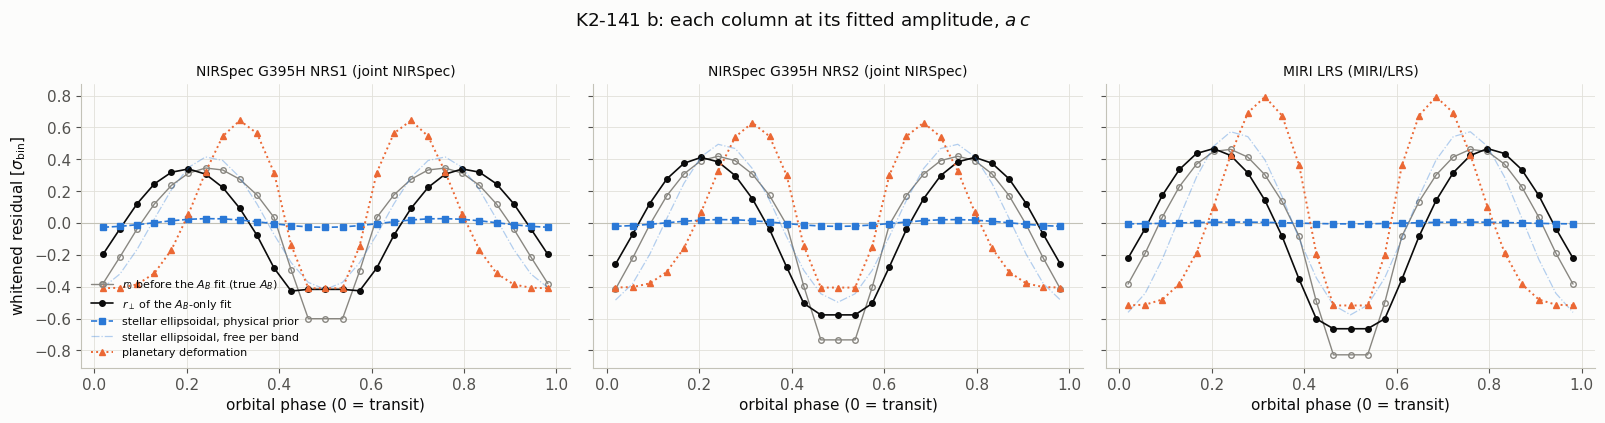

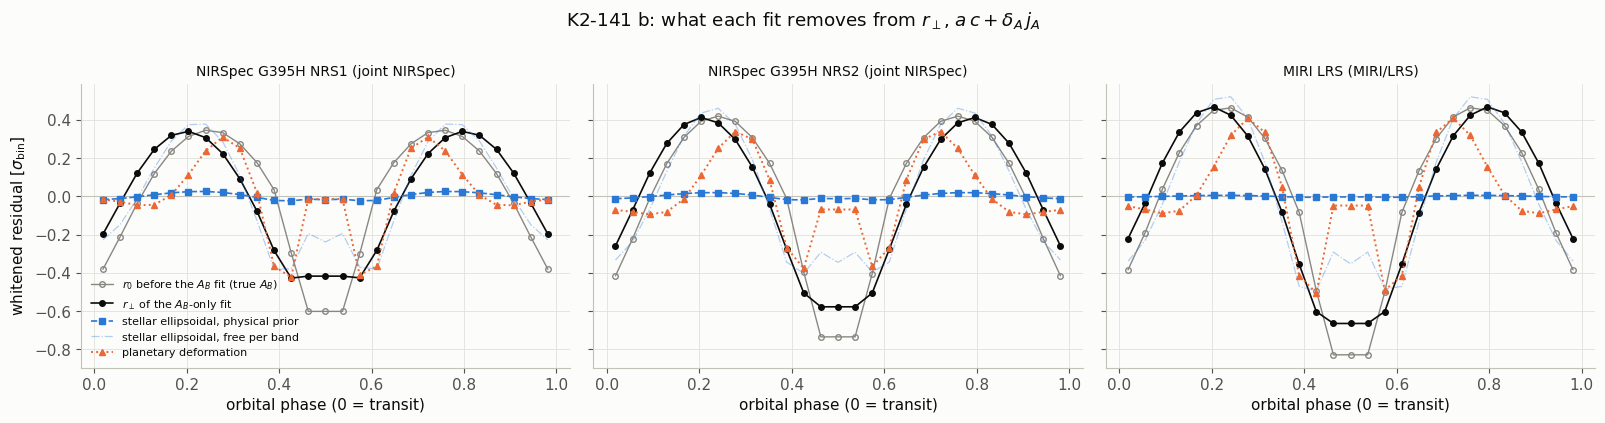

In [5]:
cosang = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))

def residual_at_truth(name, mode):
    '''Whitened residual of the point-source model at the TRUE A_B (before the A_B fit), baseline removed per detector like r_perp.'''
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return evidence_residual(c, truth, A_B_fit=A_B_true, **kw)["r_perp"]

FIG_CASES = [(name, mode) for name in PLANETS for mode in MODES if not mode.startswith("NIRSpec +")]   # the three-detector set repeats the same blocks
R0 = dict(zip(FIG_CASES, pmap(residual_at_truth, FIG_CASES)))

# The ellipsoidal terms, each fitted alone with A_B and the baseline: the stellar term with the physical prior and the planetary term as in the table; the free stellar term
# (the worst case, still a headline row) faint
TERMS = {"stellar ellipsoidal, physical prior": (("stellar_shared",), dict(marker="s", ls="--", color=C_REDIST, lw=1.2, ms=4)),
         "stellar ellipsoidal, free per band":  (("stellar",), dict(ls="-.", color=C_REDIST, lw=0.9, alpha=0.35)),
         "planetary deformation":               (("planetary",), dict(marker="^", ls=":", color=C_HI, lw=1.4, ms=4))}
# Two figures per planet: each column at its fitted amplitude (a c), and what each fit removes from r_perp (a c + delta_A j_A = r_perp - r_fit, so the gap to r_perp is what remains)
QUANTITIES = {"columns": (r"each column at its fitted amplitude, $a\,c$", lambda p, s: sum(s["delta"][n] * p["columns"][n] for n in s["names"])),
              "removed": (r"what each fit removes from $r_\perp$, $a\,c + \delta_A\,j_A$", lambda p, s: p["y"] - s["r_perp"])}

SOLS = {}
for name, mode in FIG_CASES:
    p, r0 = PROBLEMS[(name, mode)], R0[(name, mode)]
    SOLS[(name, mode)] = {label: nuisance_solve(p, nuis) for label, (nuis, _) in TERMS.items()}
    stellar_all = np.sum([p["columns"][n] for n in SOLS[(name, mode)]["stellar ellipsoidal, free per band"]["names"]], axis=0)   # all detectors with one amplitude, for the angles
    print(f"{name}, {mode}: cos(r_perp, stellar) = {cosang(p['y'], stellar_all):+.2f}, cos(r_perp, planetary) = {cosang(p['y'], p['columns']['planetary']):+.2f}, "
          f"cos(stellar, planetary) = {cosang(stellar_all, p['columns']['planetary']):+.2f}, cos(j_A, stellar) = {cosang(p['j_A'], stellar_all):+.2f}, cos(j_A, planetary) = {cosang(p['j_A'], p['columns']['planetary']):+.2f}")
    dA = p["A_B_fit"] - A_B_true
    print(f"   |r_0|^2 = {r0 @ r0:.2f} = chi2_min {p['chi2']:.2f} + albedo-like part {r0 @ r0 - p['chi2']:.2f} (linear: (dA_B |j_A|)^2 = {(dA * np.linalg.norm(p['j_A'])) ** 2:.2f});  "
          f"cos(r_0, j_A) = {cosang(r0, p['j_A']):+.2f}, cos(r_0, stellar) = {cosang(r0, stellar_all):+.2f}, cos(r_0, planetary) = {cosang(r0, p['columns']['planetary']):+.2f}")
    print("   chi2'_min / chi2_min (what remains, prior penalty included): " + ", ".join(f"{label} {s['chi2'] / p['chi2']:.2f}" for label, s in SOLS[(name, mode)].items()))

for name in PLANETS:
    modes = [m for (n, m) in FIG_CASES if n == name]
    ncol = sum(len(PROBLEMS[(name, m)]["blocks"]) for m in modes)
    for key, (what, curve) in QUANTITIES.items():
        fig, axs = plt.subplots(1, ncol, figsize=(5.4 * ncol, 4.2), sharey=True, squeeze=False)
        k = 0
        for mode in modes:
            p, r0 = PROBLEMS[(name, mode)], R0[(name, mode)]
            curves = {label: curve(p, s) for label, s in SOLS[(name, mode)].items()}
            for blk, det in zip(p["blocks"], detectors(MODES[mode])):
                ax = axs[0, k]; k += 1
                ph = p["phase"][blk]
                ax.axhline(0., color=AXIS, lw=.8)
                ax.plot(ph, r0[blk], "o-", color=MUTED, mfc="none", lw=1.0, ms=4, label=r"$r_0$ before the $A_B$ fit (true $A_B$)")
                ax.plot(ph, p["y"][blk], "o-", color=INK, lw=1.2, ms=4, label=r"$r_\perp$ of the $A_B$-only fit")
                for label, (_, style) in TERMS.items():
                    ax.plot(ph, curves[label][blk], label=label, **style)
                ax.set_title(f"{instrument_label(det, oneline=True)} ({mode})", fontsize=10); ax.set_xlabel("orbital phase (0 = transit)")
        axs[0, 0].set_ylabel(r"whitened residual [$\sigma_{\rm bin}$]"); axs[0, 0].legend(fontsize=8)
        fig.suptitle(f"{name}: {what}", y=1.0)
        fig.tight_layout()
        plt.show()

## 3. The ellipsoidal terms: physical amplitudes and the prior of the stellar term

**Star.** $A_{\rm ell} = \alpha_{\rm ell}\,(M_p/M_\star)\,(R_\star/a)^3\sin^2 i$ with $\alpha_{\rm ell} = 0.15\,(15 + u)(1 + g)/(3 - u)$ (Morris & Naftilan 1993; Shporer 2017, PASP 129, 072001), $u$ and $g$ the linear limb-darkening and the gravity-darkening coefficient of the band. Everything but $\alpha_{\rm ell}$ is the same in every band, so the physical nuisance is one amplitude for all detectors (`stellar_shared`, band ratios `STELLAR_RATIOS`, achromatic by default). Its prior (`ellipsoidal_prior`, set in the setup cell) is centred on the truth, with the uncertainty of the expected amplitude as its width: the published errors of $M_p/M_\star$, $(R_\star/a)^3$ and $\sin^2 i$ and the spread of $\alpha_{\rm ell}$ over the $(u, g)$ bracket, taken as $1\sigma$, added in quadrature (masses and sources in the setup cell). **The band coefficients are not tabulated values**: the bracket covers infrared values of K dwarfs; tabulated coefficients (e.g. Claret & Bloemen 2011, A&A 529, A75) would narrow it. $\alpha_{\rm ell}$ depends on them only through $(15+u)/(3-u)$ and $(1+g)$; across 3–10 µm it changes by less than about 10 % ($(15+u)/(3-u)$ by at most 8 % for $\Delta u = 0.2$, $(1+g)$ by a few per cent), which the band-ratio check below covers.

**Planet.** The fitted `planetary` amplitude is $\delta = (r_1 - r_2)/r_2$, the fractional difference between the cross-sections the planet shows at quadrature ($r_1 r_3$) and at conjunction ($r_2 r_3$) ($r_1$ towards the star, $r_2$ along the orbit, $r_3$ along the orbit normal). It therefore compares with $(R_1 - R_2)/R_1$. Taş et al. (2026, Sect. 6.3.1) quote $(R_1 - R_3)/R_1$ for TOI-2431 b with a fiducial Love number $h_2 = 1$. For a synchronously rotating body in equilibrium, the tidal and the centrifugal potential displace the surface by $7/6$, $-1/3$ and $-5/6$ (in units of $h_2\zeta R_p$) along $R_1$, $R_2$, $R_3$, so $R_1 - R_2 = \tfrac34(R_1 - R_3)$, as in the Correia (2014) shape of the planetary column ($r_1 = r_2(1+3q)$, $r_3 = r_2(1-q)$); the same displacements give their $R_{\rm vol} = R_{\rm tran}(1 + \tfrac{7}{12}\delta R_p)$. The cell prints both. $h_2$ itself is uncertain (about 1.9 for a fully relaxed Earth-like interior), so the published value sets the scale, not a prior.

What to look for: per planet and mode, the table steps from no stellar term over the free amplitude per band (the worst case) and the shared amplitude without a prior (what sharing alone does) to the shared amplitude with the physical prior (the realistic case, the rows `+ stellar (physical)` of section 1), and then varies the realistic case: the prior width times `PRIOR_SCALES`, and the band ratio of the last detector by `RATIO_SHIFT`. Compare the amplitudes the free fits take with the expected one above, and how far the physical prior lets the amplitude move. The effect depends on the band: the ellipsoidal variation has the same relative amplitude in every band, while the hyper-illumination residual grows with wavelength, so a stellar term of a given size absorbs more of the NIRSpec residual than of the MIRI/LRS one.

In [6]:
AXIS_RATIO = {"TOI-2431 b": (0.087, 0.017)}  # (R1 - R3) / R1 for h2 = 1: Tas et al. 2026 (A&A 707, A238) Sect. 6.3.1
R12_OVER_R13 = 0.75                          # (R1 - R2) / (R1 - R3) of a synchronously rotating body in tidal equilibrium (see above): the planetary amplitude compares with (R1 - R2) / R1
PRIOR_SCALES = (0.5, 2.)                     # sensitivity check: the prior width of the shared stellar amplitude times these
RATIO_SHIFT = 0.15                           # sensitivity check: the band ratio of the last detector of a multi-detector mode changed by this fraction

for name in PLANETS:
    e, (q, fq) = ELLIPSOIDAL[name], mass_ratio(name)
    print(f"{name}: M_p / M_star = {q:.3e} (+- {100 * fq:.0f} %)  ->  expected stellar ellipsoidal semi-amplitude {e['A']:.2f} ppm (u in {U_RANGE}, g in {G_RANGE});  "
          f"prior sigma {e['sigma']:.2f} ppm = {100 * e['frac']:.0f} % (" + ", ".join(f"{k} {100 * v:.0f} %" for k, v in e["parts"].items()) + ")")
    if name in AXIS_RATIO: print(f"   published tidal deformation (h2 = 1): (R1 - R3)/R1 = {AXIS_RATIO[name][0]:.3f} +- {AXIS_RATIO[name][1]:.3f}  ->  (R1 - R2)/R1 = {R12_OVER_R13 * AXIS_RATIO[name][0]:.3f} +- {R12_OVER_R13 * AXIS_RATIO[name][1]:.3f}, the scale of the planetary amplitude")
    rows = []
    for mode in MODES:
        p = PROBLEMS[(name, mode)]
        flat = {**p, "priors": {k: v for k, v in p["priors"].items() if k != "stellar_shared"}}
        variants = {"none": (p, ()), "free per band": (p, ("stellar",)), "shared, flat": (flat, ("stellar_shared",)), "shared, physical prior": (p, ("stellar_shared",))}
        for f in PRIOR_SCALES:
            variants[f"shared, prior x {f:g}"] = ({**p, "priors": {**p["priors"], "stellar_shared": f * p["priors"]["stellar_shared"]}}, ("stellar_shared",))
        if len(p["blocks"]) > 1:
            for f in (1. - RATIO_SHIFT, 1. + RATIO_SHIFT):
                r = p["stellar_ratios"].copy(); r[-1] *= f
                variants[f"shared, last band ratio x {f:g}"] = ({**p, "columns": {**p["columns"], "stellar_shared": stellar_shared_column(p["columns"], r)}}, ("stellar_shared",))
        for label, (pp, nuis) in variants.items():
            s = nuisance_solve(pp, nuis)
            rows.append({"mode": mode, "stellar term": label, "sigma_A_B": s["sigma_A_B"], "bias_sigma": abs(s["A_B_fit"] - A_B_true) / s["sigma_A_B"], "lnB_mean": s["lnB_mean"],
                         "amplitude [ppm]": ", ".join(f"{s['delta'][n]:.1f} +- {s['sigma_post'][n]:.1f}" for n in s["names"]) or "-"})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
    print("   planetary amplitude fitted alone: " + ";  ".join(f"{m} {TABLES[(name, m)].set_index('row').loc['+ planetary', 'planetary']:.3f} +- {TABLES[(name, m)].set_index('row').loc['+ planetary', 'sig planetary']:.3f}" for m in MODES), "\n")

TOI-2431 b: M_p / M_star = 2.817e-05 (+- 26 %)  ->  expected stellar ellipsoidal semi-amplitude 2.96 ppm (u in (0.1, 0.3), g in (0.1, 0.4));  prior sigma 0.92 ppm = 31 % (M_p / M_star 26 %, (R_star / a)^3 6 %, sin^2 i 1 %, alpha_ell (u, g) 16 %)
   published tidal deformation (h2 = 1): (R1 - R3)/R1 = 0.087 +- 0.017  ->  (R1 - R2)/R1 = 0.065 +- 0.013, the scale of the planetary amplitude
         mode                   stellar term  sigma_A_B  bias_sigma  lnB_mean                    amplitude [ppm]
joint NIRSpec                           none     0.0266         1.6      5.79                                  -
joint NIRSpec                  free per band     0.0298      0.0749      1.21             3.0 +- 1.5, 4.6 +- 1.8
joint NIRSpec                   shared, flat     0.0298       0.089      1.45                         3.6 +- 1.2
joint NIRSpec         shared, physical prior     0.0278        1.01      4.21                         1.3 +- 0.7
joint NIRSpec            shared, prior x 0.5 

## 4. Checks

**Step size of the geometry columns.** The same tables with every finite-difference step doubled (`NUISANCE_STEPS` × 2): the relative change of each column and the largest relative change of $\sigma_{A_B}$ and $\chi^{2\prime}_{\min}$ over all rows.

**Nonlinear refit.** For the cases and rows of `NL_CHECKS` (TOI-2431 b in MIRI/LRS, and in the joint NIRSpec fit the rows whose columns combine detectors or parameters: $b$, the shared stellar term), the full nonlinear least-squares fit (`nuisance_fit_nonlinear`: the point-source model re-evaluated at every step, $i$ from $b$ where $b$ is fitted, priors as residual rows, baselines by mean removal) against the linear rows: $\hat A_B$, $\sigma_{A_B}$ from the Jacobian at the solution, and $\chi^2_{\min}$.

What to look for: the linear and the nonlinear numbers agree where the fit moves little (geometry rows). Where an ellipsoidal term shifts $A_B$ by more than its $\sigma$, the response to $A_B$ is no longer linear over the shift ($T \propto (1-A_B)^{1/4}$) and the two differ in $\hat A_B$ and $\sigma_{A_B}$, while $\chi^2_{\min}$, the quantity the evidence rests on, stays close.

In [7]:
def case_2h(name, mode):
    pl = hi_planets_by_name(name)
    c = retrieval_cfg(cfg, pl, MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, steps={k: 2. * v for k, v in NUISANCE_STEPS.items()}, **kw)

P2 = dict(zip(CASES, pmap(case_2h, CASES)))
print(f"steps {NUISANCE_STEPS} against twice these:")
for k in CASES:
    t1, t2 = TABLES[k], nuisance_table(P2[k], A_B_true, ROWS[k[0]])
    cols = ", ".join(f"{n} {np.linalg.norm(PROBLEMS[k]['columns'][n] - P2[k]['columns'][n]) / np.linalg.norm(PROBLEMS[k]['columns'][n]):.1e}" for n in GEOM)
    print(f"   {k[0]:11s} {k[1]:14s} relative change of the columns: {cols};  max over rows: sigma_A_B {np.max(np.abs(t2['sigma_A_B'] / t1['sigma_A_B'] - 1.)):.1e}, chi2 {np.max(np.abs(t2['chi2'] / t1['chi2'] - 1.)):.1e}")

steps {'a_rs': 0.005, 'rp_rs': 0.0001, 'incl': 0.2} against twice these:
   TOI-2431 b  joint NIRSpec  relative change of the columns: a_rs 4.2e-03, rp_rs 1.3e-06, incl 1.5e-03;  max over rows: sigma_A_B 2.7e-03, chi2 1.4e-03
   TOI-2431 b  MIRI/LRS       relative change of the columns: a_rs 6.0e-03, rp_rs 1.6e-06, incl 1.7e-03;  max over rows: sigma_A_B 1.1e-03, chi2 1.1e-03
   TOI-2431 b  NIRSpec + LRS  relative change of the columns: a_rs 4.6e-03, rp_rs 1.4e-06, incl 1.6e-03;  max over rows: sigma_A_B 3.6e-03, chi2 1.9e-03
   K2-141 b    joint NIRSpec  relative change of the columns: a_rs 6.8e-03, rp_rs 6.7e-08, incl 2.2e-03;  max over rows: sigma_A_B 3.3e-04, chi2 4.5e-04
   K2-141 b    MIRI/LRS       relative change of the columns: a_rs 8.5e-03, rp_rs 1.1e-07, incl 2.9e-03;  max over rows: sigma_A_B 1.5e-04, chi2 3.2e-04
   K2-141 b    NIRSpec + LRS  relative change of the columns: a_rs 7.1e-03, rp_rs 7.5e-08, incl 2.3e-03;  max over rows: sigma_A_B 3.3e-04, chi2 5.2e-04


In [8]:
# The linear rows against nonlinear least-squares fits: every row of interest for TOI-2431 b in MIRI/LRS, and for the joint NIRSpec fit the rows whose columns combine detectors (b, the shared stellar term)
NL_CHECKS = {("TOI-2431 b", "MIRI/LRS"): ["+ all geometry", "+ stellar (physical)", "+ geometry + stellar (physical)", "+ stellar (free per band)", "+ planetary", "+ geometry + planetary"],
             ("TOI-2431 b", "joint NIRSpec"): ["+ all geometry", "+ stellar (physical)", "+ geometry + stellar (physical)", "+ stellar (free per band)"]}
NL_JOBS = [(key, label) for key, labels in NL_CHECKS.items() for label in labels]

def nonlinear(key, label):
    name, mode = key
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_fit_nonlinear(c, truth, ROWS[name][label], priors=PROBLEMS[key]["priors"], stellar_ratios=STELLAR_RATIOS, **kw)

NL = dict(zip(NL_JOBS, pmap(nonlinear, NL_JOBS)))
for key, labels in NL_CHECKS.items():
    p = PROBLEMS[key]
    lin = {label: nuisance_solve(p, ROWS[key[0]][label]) for label in labels}
    print(f"{key[0]}, {key[1]}: linear rows against the nonlinear least-squares fit")
    print(pd.DataFrame([{"row": label, "A_B lin": lin[label]["A_B_fit"], "A_B nonlin": NL[(key, label)]["A_B_fit"], "sigma lin": lin[label]["sigma_A_B"], "sigma nonlin": NL[(key, label)]["sigma_A_B"],
                         "chi2 lin": lin[label]["chi2"], "chi2 nonlin": NL[(key, label)]["chi2"], "nfev": NL[(key, label)]["nfev"]} for label in labels]).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    print("fitted nuisances, linear | nonlinear (value +- sigma):")
    for label in labels:
        nl = NL[(key, label)]
        print(f"   {label}: " + ";  ".join(f"{n} {p['values'].get(n, 0.) + lin[label]['delta'][n]:.5g} +- {lin[label]['sigma_post'][n]:.2g} | {nl['values'][n]:.5g} +- {nl['sigma_post'][n]:.2g}" for n in lin[label]["names"]))
    print()

TOI-2431 b, MIRI/LRS: linear rows against the nonlinear least-squares fit
                            row  A_B lin  A_B nonlin  sigma lin  sigma nonlin  chi2 lin  chi2 nonlin  nfev
                 + all geometry   0.1516      0.1507     0.0774       0.07664     12.17        12.17    20
           + stellar (physical)   0.1505      0.1505    0.05397       0.05351     11.53        11.53    26
+ geometry + stellar (physical)   0.1556      0.1557    0.07751       0.07643      11.2         11.2    16
      + stellar (free per band)   0.2277      0.2246    0.06022       0.05591     3.172        3.172    12
                    + planetary   0.3187      0.3112    0.09765       0.08885     7.892        7.927    20
         + geometry + planetary   0.3267      0.3184     0.1143        0.1009     7.837        7.867    18
fitted nuisances, linear | nonlinear (value +- sigma):
   + all geometry: a_rs|b 2.0691 +- 0.03 | 2.0689 +- 0.03;  rp_rs 0.021307 +- 0.00013 | 0.021305 +- 0.00013;  b 0.57548 +-

## 5. Both point-source fits with the same nuisances

Sections 1–4 treat the $A_B$-only fit. The fit with redistribution cannot be linearised around that fit, which sits at the $F = 0$ edge, but it can around its own noiseless solution $(\hat A_B, \hat F)$ (`fit_redist`), where $\hat F > 0$ and the response to $F$ is regular. `nuisance_problem(..., redist=True)` builds that problem: $y$ the residual of the joint fit, $X = [j_A, j_F, j_{\nu_1}, \dots]$ with every column the derivative of the point-source model with redistribution at $(\hat A_B, \hat F)$. `nuisance_solve` solves either problem, and `nuisance_both_fits` returns for one row the statistics of the paper for both fits: the bias $\Delta A_B$, $\sigma_{A_B}$ and their ratio, $\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$ of the $A_B$-only fit, and for the fit with redistribution (suffix `_J`) $\hat F$ and
$$z_F' = \sqrt{\chi^{2\prime}_{\min}(A_B, \nu) - \chi^{2\prime}_{\min}(A_B, F, \nu)},$$
the significance of the spurious redistribution when both fits carry the nuisances $\nu$. Where the shifted solution has $F \leq 0$, the fit with redistribution is the $A_B$-only fit and $z_F' = 0$.

The rows (`ROWS_BOTH`) are nested the way an analysis is built up: the geometry fixed, the geometry free, and then one ellipsoidal term added to the free geometry (the stellar term with its physical prior, free per band, and the planetary term free; section 7 gives the planetary term its physical range).

**Check.** The row with free geometry against a nonlinear least-squares fit of $(A_B, F,$ geometry$)$ started at the joint fit (`nuisance_fit_nonlinear(..., redist=True)`). The free-geometry dynesty runs (`retrievals/03_retrieval_series.ipynb`, section 6) are the independent reference for these rows: the paired median differences, the posterior widths, the geometry shifts and $z_F$ of the runs against the numbers here.

What to look for:
- **Which results need the fixed geometry.** The significance of the albedo bias of both fits against $z_F$ and $\langle\ln B\rangle$ from the first to the second row: the albedo trades against $R_p/R_\star$, which scales the planet's flux, and against $a/R_\star$, which sets the irradiation; the shape of the light curve does not depend on either in that way.
- **Where the bias goes.** The second table gives the shift of each geometry parameter in units of its prior: the point-source fit moves the planet inward (smaller $a/R_\star$), and the fit with redistribution enlarges the planet.
- **What each ellipsoidal term absorbs**: the evidence, $z_F$ and the bias react differently to the stellar and to the planetary term, and to the prior of the stellar one. The amplitude that a free stellar term takes (section 1) is then biased in place of the albedo.

In [9]:
# The fit with redistribution as a linear problem around its own noiseless solution (nuisance_problem(..., redist=True)), paired with the A_B-only problems of section 1
def case_redist(name, mode):
    '''case() for the fit with redistribution: the nuisance problem around its noiseless solution (A_B_fit, F_fit).'''
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, redist=True, **kw)

KEYS = [(name, mode) for name in PLANETS for mode in FIGURE_MODES]
RPROBLEMS = dict(zip(KEYS, pmap(case_redist, KEYS)))

def both_fits(key, nuisances=(), priors=None, time_factor=1., limits=None):
    '''Both point-source fits of one case (planet, mode) with the same nuisances (nuisance_both_fits).'''
    return nuisance_both_fits(PROBLEMS[key], RPROBLEMS[key], A_B_true, nuisances, priors, time_factor, limits)

def rows_both(name):
    geom = ROWS[name]["+ all geometry"]
    return {"fixed geometry": (), "free geometry": geom, "free geometry + stellar (physical)": (*geom, "stellar_shared"), "free geometry + stellar (free per band)": (*geom, "stellar"), "free geometry + planetary": (*geom, "planetary")}

ROWS_BOTH = {name: rows_both(name) for name in PLANETS}
BOTH = {k: {label: both_fits(k, nuis) for label, nuis in ROWS_BOTH[k[0]].items()} for k in KEYS}

HEAD_BOTH = {"bias": "ΔA_B", "bias_sigma": "|ΔA_B|/σ", "lnB_mean": "⟨ln B⟩", "bias_J": "ΔA_B (F)", "bias_sigma_J": "|ΔA_B|/σ (F)", "F_fit": "F", "z_F": "z_F"}
for name in PLANETS:
    summary = pd.concat({mode: pd.DataFrame({label: {HEAD_BOTH[c]: b[c] for c in HEAD_BOTH} for label, b in BOTH[(name, mode)].items()}).T for mode in FIGURE_MODES}, axis=1)
    display(summary.style.format("{:.3g}").set_caption(f"{name}: the A_B-only fit (ΔA_B, |ΔA_B|/σ, ⟨ln B⟩) and the fit with redistribution (F) with the same nuisances"))
    shifts = pd.DataFrame({mode: {fit: " · ".join(f"{SHORT[n]} {BOTH[(name, mode)]['free geometry'][key]['delta'][n] / PROBLEMS[(name, mode)]['priors'][n]:+.2f}" for n in ROWS[name]["+ all geometry"])
                                  for fit, key in (("A_B-only", "fit"), ("with redistribution", "fit_J"))} for mode in FIGURE_MODES})
    display(shifts.style.set_caption(f"{name}, free geometry: shift of each geometry parameter in units of its prior σ"))

,joint NIRSpec,MIRI/LRS
A_B-only,a/R* -0.28 · Rp/R* +0.06 · b +0.19,a/R* -0.27 · Rp/R* -0.01 · b +0.07
with redistribution,a/R* -0.07 · Rp/R* +0.24 · b +0.02,a/R* -0.07 · Rp/R* +0.48 · b -0.07


,joint NIRSpec,MIRI/LRS
A_B-only,a/R* -0.10 · Rp/R* +0.06 · i -0.10,a/R* -0.13 · Rp/R* +0.04 · i -0.01
with redistribution,a/R* -0.03 · Rp/R* +0.17 · i -0.03,a/R* -0.05 · Rp/R* +0.34 · i +0.02


In [10]:
# Check of the free-geometry row of the fit with redistribution: nonlinear least squares over (A_B, F, geometry), started at the noiseless joint fit (F > 0, away from the F = 0 edge)
def nonlinear_redist(name, mode):
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_fit_nonlinear(c, truth, ROWS[name]["+ all geometry"], priors=PROBLEMS[(name, mode)]["priors"], stellar_ratios=STELLAR_RATIOS, redist=True, **kw)

NL_F = dict(zip(KEYS, pmap(nonlinear_redist, KEYS)))
print("fit with redistribution, free geometry: linear row | nonlinear least squares")
for k in KEYS:
    lin, nl = BOTH[k]["free geometry"]["fit_J"], NL_F[k]
    print(f"   {k[0]:11s} {k[1]:14s} A_B {lin['A_B_fit']:.4f} | {nl['A_B_fit']:.4f};  F {lin['F_fit']:.4f} | {nl['F_fit']:.4f};  sigma_A_B {lin['sigma_A_B']:.4f} | {nl['sigma_A_B']:.4f};  chi2 {lin['chi2']:.3f} | {nl['chi2']:.3f}")

fit with redistribution, free geometry: linear row | nonlinear least squares
   TOI-2431 b  joint NIRSpec  A_B 0.1298 | 0.1289;  F 0.0168 | 0.0171;  sigma_A_B 0.0467 | 0.0455;  chi2 3.523 | 3.510
   TOI-2431 b  MIRI/LRS       A_B 0.0907 | 0.0884;  F 0.0076 | 0.0078;  sigma_A_B 0.0880 | 0.0826;  chi2 2.301 | 2.304
   K2-141 b    joint NIRSpec  A_B 0.1407 | 0.1395;  F 0.0126 | 0.0129;  sigma_A_B 0.0580 | 0.0565;  chi2 1.805 | 1.793
   K2-141 b    MIRI/LRS       A_B 0.1064 | 0.1039;  F 0.0054 | 0.0056;  sigma_A_B 0.1324 | 0.1237;  chi2 0.925 | 0.923


**Figure.** The rows of `ROWS_BOTH` for both fits in the two primary modes, one line of panels per planet: the significance of the albedo bias (both fits), the significance $z_F$ of the spurious redistribution, and the expected evidence. Colour and symbol give the fit, as in the retrieval figures (grey circles: $A_B$-only; blue squares: with redistribution); filled symbols are the joint NIRSpec fit, open ones MIRI/LRS. The dashed lines mark $1\sigma$, $z_F = 2$, and the evidence thresholds 2.5 and 5.

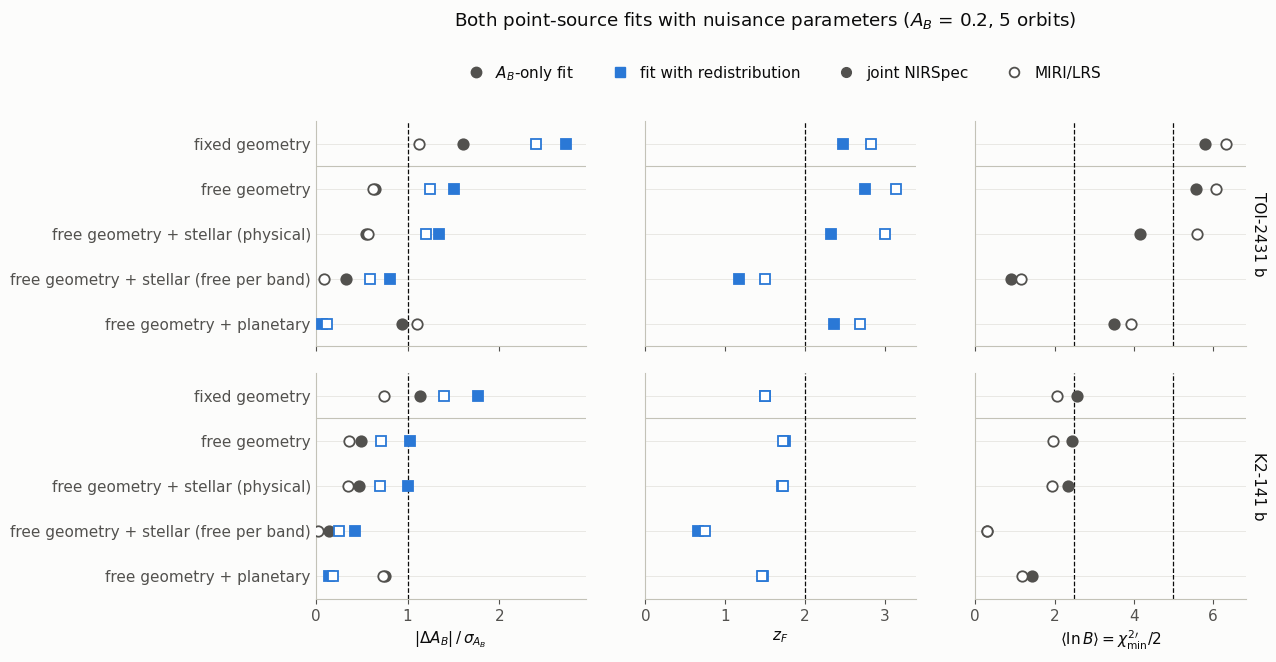

In [11]:
# Dot plot of ROWS_BOTH: per planet the albedo bias of both fits, z_F and <ln B>; colour and symbol = fit (as in the retrieval figures), filled = joint NIRSpec, open = MIRI/LRS
rows_fig = list(ROWS_BOTH[PLANETS[0]])
ypos = np.arange(len(rows_fig))
PANELS = ((r"$|\Delta A_B|\,/\,\sigma_{A_B}$", (("bias_sigma", C_NAIVE, "o"), ("bias_sigma_J", C_REDIST, "s")), (1.,)), (r"$z_F$", (("z_F", C_REDIST, "s"),), (2.,)),
          (r"$\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$", (("lnB_mean", C_NAIVE, "o"),), (2.5, 5.)))
FILL = dict(zip(FIGURE_MODES, (True, False)))
xmax = [1.08 * max(BOTH[k][r][col] for k in KEYS for r in rows_fig for col, *_ in cols) for _, cols, _ in PANELS]   # one x scale per quantity

fig, axs = plt.subplots(len(PLANETS), len(PANELS), figsize=(12., 1.1 + 0.42 * len(rows_fig) * len(PLANETS) + 0.9), sharey=True, sharex="col", squeeze=False, gridspec_kw=dict(wspace=0.22, hspace=0.12))
for i, name in enumerate(PLANETS):
    for j, (xlabel, cols, refs) in enumerate(PANELS):
        ax = axs[i, j]
        ax.grid(False)
        for yy in ypos: ax.axhline(yy, color="#e6e5e0", lw=0.6, zorder=0)
        ax.axhline(0.5, color=AXIS, lw=0.8, zorder=0)   # the fixed-geometry row apart from the rest
        for v in refs: ax.axvline(v, color=INK, lw=0.9, ls="--", zorder=1)
        for mode in FIGURE_MODES:
            for col, colour, marker in cols:
                ax.plot([BOTH[(name, mode)][r][col] for r in rows_fig], ypos, marker, ls="none", color=colour, mfc=colour if FILL[mode] else "white", ms=7.5 if marker == "o" else 6.5, mew=1.3, zorder=3)
        ax.set_xlim(0., xmax[j])
        if i == len(PLANETS) - 1: ax.set_xlabel(xlabel)
    axs[i, 0].set_yticks(ypos, rows_fig)
    axs[i, -1].annotate(name, (1.02, 0.5), xycoords="axes fraction", rotation=270, va="center", fontsize=11)
axs[0, 0].set_ylim(len(rows_fig) - 0.5, -0.5)
for ax in axs.ravel(): ax.tick_params(axis="y", length=0)
handles = [plt.Line2D([], [], marker="o", ls="none", color=C_NAIVE, ms=7.5, label=r"$A_B$-only fit"), plt.Line2D([], [], marker="s", ls="none", color=C_REDIST, ms=6.5, label="fit with redistribution"),
           plt.Line2D([], [], marker="o", ls="none", color=INK_2, ms=7, label=FIGURE_MODES[0]), plt.Line2D([], [], marker="o", ls="none", color=INK_2, mfc="white", ms=7, mew=1.3, label=FIGURE_MODES[1])]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5 * (axs[0, 0].get_position().x0 + axs[0, -1].get_position().x1), 0.995), handletextpad=0.3)   # centred on the panels
fig.suptitle(rf"Both point-source fits with nuisance parameters ($A_B$ = {A_B_true:g}, {n_orbits} orbits)", y=1.06)
plt.show()

## 6. What the albedo bias with a free geometry depends on

With the geometry free, the point-source fit shares the mismatch between the albedo and the geometry, and the priors decide how. Two scans of the row `free geometry` for both fits (`both_fits`), next to the fixed-geometry fit:
- **the width of the geometry priors**, all three scaled by a common factor (`PRIOR_FACTORS`; 1 = the published uncertainties, towards 0 the fixed-geometry fit);
- **the observing time** (`ORBITS`), with the priors as published: the data rows scale with $\sqrt{n_{\rm orbits}}$, the prior rows do not, so the result is not a simple $\sqrt{n_{\rm orbits}}$ scaling of the 5-orbit row.

Both scans are linear extrapolations around the fits of section 1 and 5. The table prints the shift of $a/R_\star$ in units of its (scaled) prior; where it exceeds about one, the geometry has left the range in which the columns were differentiated and the numbers are indicative only (section 4 has the nonlinear check at factor 1).

What to look for: at fixed geometry every significance grows as $\sqrt{n_{\rm orbits}}$. With the geometry free, compare how the significance of the $A_B$-only bias, that of the fit with redistribution, $z_F$ and $\langle\ln B\rangle$ grow with the observing time, and the sign of $\Delta A_B$ of the $A_B$-only fit as the priors widen: the wider the priors or the longer the observation, the more of the mismatch the geometry takes.

TOI-2431 b, joint NIRSpec: width of the geometry priors x factor (5 orbits)
           ΔA_B  |ΔA_B|/σ  ⟨ln B⟩  ΔA_B (F)  |ΔA_B|/σ (F)  z_F  a/R* shift / prior
factor                                                                            
0.25    -0.0356      1.09    5.65   -0.0796          2.11 2.69              -0.176
0.50    -0.0332      0.92    5.62    -0.074          1.84 2.75              -0.186
1.00    -0.0269     0.642    5.57   -0.0702          1.51 2.76              -0.278
2.00   -0.00417     0.072    5.41   -0.0632          0.97 2.71              -0.493
3.00     0.0307     0.403    5.16   -0.0528         0.604 2.63              -0.691
TOI-2431 b, joint NIRSpec: observing time, published priors (fixed | free geometry)
       fixed geometry free geometry fixed geometry free geometry fixed geometry free geometry fixed geometry free geometry
           bias_sigma    bias_sigma   bias_sigma_J  bias_sigma_J            z_F           z_F       lnB_mean      lnB_mean
orbits       

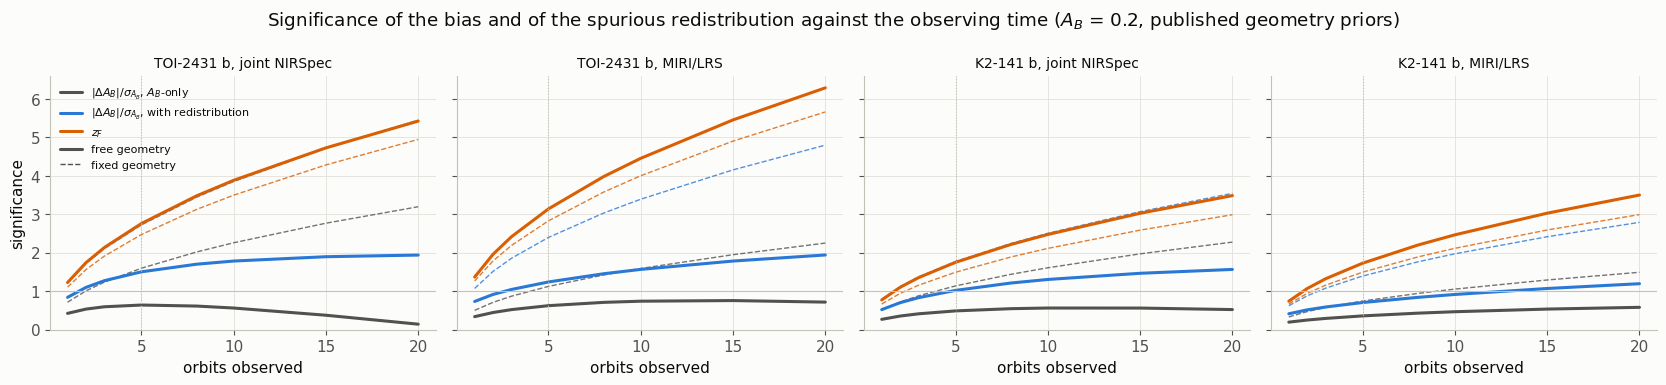

In [12]:
PRIOR_FACTORS = (0.25, 0.5, 1., 2., 3.)
ORBITS = (1, 2, 3, 5, 8, 10, 15, 20)
SCAN_COLS = {"bias": "ΔA_B", "bias_sigma": "|ΔA_B|/σ", "lnB_mean": "⟨ln B⟩", "bias_J": "ΔA_B (F)", "bias_sigma_J": "|ΔA_B|/σ (F)", "z_F": "z_F"}

def scan_row(key, priors=None, time_factor=1.):
    geom = ROWS[key[0]]["+ all geometry"]
    b = both_fits(key, geom, priors, time_factor)
    width = (priors or PROBLEMS[key]["priors"])[geom[0]]
    return {**{head: b[c] for c, head in SCAN_COLS.items()}, "a/R* shift / prior": b["fit"]["delta"][geom[0]] / width}

TIME = {}
for k in KEYS:
    geom = ROWS[k[0]]["+ all geometry"]
    print(f"{k[0]}, {k[1]}: width of the geometry priors x factor ({n_orbits} orbits)")
    print(pd.DataFrame({f: scan_row(k, priors={n: f * PROBLEMS[k]["priors"][n] for n in geom}) for f in PRIOR_FACTORS}).T.rename_axis("factor").to_string(float_format=lambda v: f"{v:.3g}"))
    TIME[k] = {"fixed geometry": pd.DataFrame({n: {c: both_fits(k, (), time_factor=n / n_orbits)[c] for c in SCAN_COLS} for n in ORBITS}).T,
               "free geometry": pd.DataFrame({n: {c: both_fits(k, geom, time_factor=n / n_orbits)[c] for c in SCAN_COLS} for n in ORBITS}).T}
    print(f"{k[0]}, {k[1]}: observing time, published priors (fixed | free geometry)")
    print(pd.concat(TIME[k], axis=1)[[(g, c) for c in ("bias_sigma", "bias_sigma_J", "z_F", "lnB_mean") for g in TIME[k]]].rename_axis("orbits").to_string(float_format=lambda v: f"{v:.3g}"), "\n")

# Figure: the three significances against the observing time, one column per case. One colour per quantity (grey, blue, orange); thick solid = free geometry, thin dashed = fixed
CURVES = (("bias_sigma", C_NAIVE, r"$|\Delta A_B|/\sigma_{A_B}$, $A_B$-only"), ("bias_sigma_J", C_REDIST, r"$|\Delta A_B|/\sigma_{A_B}$, with redistribution"), ("z_F", "#d95f02", r"$z_F$"))
fig, axs = plt.subplots(1, len(KEYS), figsize=(4.2 * len(KEYS), 3.9), sharey=True, squeeze=False)
for ax, k in zip(axs[0], KEYS):
    for col, colour, label in CURVES:
        ax.plot(ORBITS, TIME[k]["fixed geometry"][col], "--", color=colour, lw=1.0, alpha=0.8)
        ax.plot(ORBITS, TIME[k]["free geometry"][col], "-", color=colour, lw=2.2, label=label)
    ax.axhline(1., color=AXIS, lw=0.8); ax.axvline(n_orbits, color=AXIS, lw=0.8, ls=":")
    ax.set_title(f"{k[0]}, {k[1]}", fontsize=10); ax.set_xlabel("orbits observed")
axs[0, 0].set_ylabel("significance"); axs[0, 0].set_ylim(0., 6.6)
handles = [plt.Line2D([], [], color=colour, lw=2.2, label=label) for _, colour, label in CURVES] + [plt.Line2D([], [], color=INK_2, lw=2.2, label="free geometry"), plt.Line2D([], [], color=INK_2, lw=1.0, ls="--", label="fixed geometry")]
axs[0, 0].legend(handles=handles, fontsize=8, loc="upper left")
fig.suptitle(rf"Significance of the bias and of the spurious redistribution against the observing time ($A_B$ = {A_B_true:g}, published geometry priors)")
fig.tight_layout()
plt.show()

## 7. Further nuisances and checks

- **Stellar effective temperature.** The planet's temperature scales with $T_{\rm eff}$, so in the energy balance $T_{\rm eff}$ is degenerate with $(1 - A_B)^{1/4}$; in the flux ratio part of it cancels against the stellar band flux, the more the closer the band is to the Rayleigh–Jeans regime. It is the column `T_s` of every nuisance problem (the derivative in $T_{\rm eff}$ at fixed $\log g$ and [Fe/H]), here with a Gaussian prior `SIGMA_TEFF`: the published uncertainty and, where that is a formal error below the systematic floor of about 2 % (Tayar et al. 2022), also 80 K.
- **Planetary deformation within its physical range.** The row `+ planetary` leaves the amplitude free, which no physical model allows: a body in hydrostatic equilibrium has a fluid Love number $1 \leq h_2 \leq 2.5$ (all mass at the centre to homogeneous), and the amplitude is $\delta = 1.5\,h_2\,(M_\star/M_p)(R_p/a)^3$ (`deformation_amplitude`; section 3). The row of the paper's nuisance figure (Sec. 4.4) takes a planet with the true Love number `DEFORMATION_H2_TRUE` and gives $h_2$ a flat prior over `DEFORMATION_H2_RANGE` (`deformation_limits`, passed as `uniform` to `nuisance_both_fits`): what a retrieval with that prior gives, exact for the linear problem (`bounded_posterior`). The column is linear in the amplitude, so only the shift from the true value enters and the truth stays a sphere. A free amplitude would exceed the upper limit, so the best fit within the range (`limits`, the next row) ends on it; the posterior does not, because the likelihood falls off slowly enough across the range that it spreads over its upper part. The range cuts off most of the point-source likelihood and less of the extended-source one, so the Occam factors no longer cancel: $\langle\ln B\rangle = \chi^{2\prime}_{\rm free}/2 + \ln(m_{\rm ext}/m_{\rm ps})$, with $\chi^{2\prime}_{\rm free}$ the fit with the amplitude unbounded and $m$ the share of each model's likelihood within the range, not $\chi^{2\prime}_{\min}/2$ of the best fit. The bias of this row is the difference between the posterior medians of $A_B$ of the point-source and the extended-source model (the latter moves off the truth, since the range is not symmetric about the true $h_2$), $\sigma_{A_B}$ the posterior width of the point-source fit, and $z_F$ the likelihood ratio of the best fits, as for a retrieval. For comparison the table also has the best fit, a Gaussian prior standing in for the range (`deformation_prior`: the standard deviation of a uniform distribution over the range, centred on the truth), whose result depends on that assumed shape, and the free amplitude.
- **Nonlinear checks of the deformation rows.** `nuisance_fit_nonlinear(..., limits=...)` fits $(A_B, [F,]$ geometry, deformation$)$ with the range as bounds of the solver and the exact projected-area factor, for both fits of every case: the best fit, which ends on the upper limit, and, since the posterior of the uniform prior rests on the likelihood across the whole range, the fits with the deformation held at the lower limit and at the true value (last cell).
- **Binning.** The geometry columns contain the transit, which 27 bins per orbit do not resolve. The headline rows again with `N_BINS_CHECK` bins per orbit.

What to look for: how much each prior on $T_{\rm eff}$ adds to $\sigma_{A_B}$ of the free-geometry row; the amplitude a free deformation takes against the room that the limits leave (it adds to the true deformation, which the truth here does not have), how the treatments of the deformation differ in the bias, the evidence and $z_F$ (above all the best fit against the posterior of the same range), whether the nonlinear fit ends on the same limit with the same numbers, and whether the linear $\chi^2$ holds across the range; and whether the free-geometry row moves with the binning by more than the fixed-geometry row does.

In [13]:
SIGMA_TEFF = {"TOI-2431 b": (28., 80.),   # [K] Tas et al. 2026: T_eff = 4109 +- 28 K (formal), and a 2 % systematic floor
              "K2-141 b": (79.,)}          # [K] Malavolta et al. 2018: 4599 +- 79 K
DEFORMATION = {name: deformation_prior(hi_planets_by_name(name), mass_ratio(name)[0]) for name in PLANETS}   # the amplitude of the planetary term over the Love-number range 1 <= h2 <= 2.5
LIMITS = {name: {"planetary": deformation_limits(hi_planets_by_name(name), mass_ratio(name)[0], DEFORMATION_H2_TRUE, DEFORMATION_H2_RANGE)} for name in PLANETS}   # the shift of that amplitude a fit may make for a planet with h2 = DEFORMATION_H2_TRUE
N_BINS_CHECK = 135

show = lambda b: {head: b[c] for c, head in {"sigma": "σ_AB", **SCAN_COLS}.items()}
for k in KEYS:
    geom, deform = ROWS[k[0]]["+ all geometry"], DEFORMATION[k[0]]
    rows = {"fixed geometry": show(both_fits(k)), "free geometry": show(both_fits(k, geom))}
    for s in SIGMA_TEFF[k[0]]: rows[f"free geometry + T_eff ({s:g} K)"] = show(both_fits(k, (*geom, "T_s"), {"T_s": s}))
    uni = nuisance_both_fits(PROBLEMS[k], RPROBLEMS[k], A_B_true, (*geom, "planetary"), uniform=LIMITS[k[0]])   # flat prior over the range: the row of the paper
    rows[f"free geometry + planetary (flat prior on h2 <= {DEFORMATION_H2_RANGE[1]:g}, true h2 = {DEFORMATION_H2_TRUE:g})"] = show(uni)
    rows["free geometry + planetary (best fit within the same range)"] = show(both_fits(k, (*geom, "planetary"), limits=LIMITS[k[0]]))
    rows["free geometry + planetary (Gaussian prior)"] = show(both_fits(k, (*geom, "planetary"), {"planetary": deform["sigma"]}))
    rows["free geometry + planetary (free)"] = show(both_fits(k, (*geom, "planetary")))
    free, lim = both_fits(k, (*geom, "planetary"))["fit"], LIMITS[k[0]]["planetary"]
    print(f"{k[0]}, {k[1]}  (planetary amplitude for h2 = 1 to 2.5: {deform['lo']:.3f} to {deform['hi']:.3f}; limits of its shift from h2 = {DEFORMATION_H2_TRUE:g}: {lim[0]:+.3f} to {lim[1]:+.3f}; sigma of the Gaussian prior {deform['sigma']:.3f}; "
          f"a free amplitude takes {free['delta']['planetary']:.3f} +- {free['sigma_post']['planetary']:.3f} on top of the true one)")
    print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3g}"))
    po = uni["posterior"]
    print(f"   flat prior: posterior shift of the deformation {po['ps']['x_mean']:+.4f} +- {po['ps']['x_sd']:.4f} (point source) and {po['ext']['x_mean']:+.4f} +- {po['ext']['x_sd']:.4f} (extended source); "
          f"share of the likelihood within the range {po['ps']['mass']:.3f} and {po['ext']['mass']:.3f}; posterior medians of A_B {uni['fit']['A_B_fit']:.4f} and {po['ext']['median'][0]:.4f}\n")

# --- binning: the headline rows of the A_B-only fit at N_BINS_CHECK bins per orbit
def case_bins(name, mode):
    c = retrieval_cfg(replace(cfg, n_bins=N_BINS_CHECK), hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, **kw)

PB = dict(zip(KEYS, pmap(case_bins, KEYS)))
print(f"{n_bins} | {N_BINS_CHECK} bins per orbit:")
for k in KEYS:
    t1, t2 = TABLES[k].set_index("row"), nuisance_table(PB[k], A_B_true, ROWS[k[0]]).set_index("row")
    print(f"   {k[0]}, {k[1]}: " + ";  ".join(f"{r}: |ΔA_B|/σ {t1.loc[r, 'bias_sigma']:.2f} | {t2.loc[r, 'bias_sigma']:.2f}, σ_AB {t1.loc[r, 'sigma_A_B']:.4f} | {t2.loc[r, 'sigma_A_B']:.4f}, ⟨ln B⟩ {t1.loc[r, 'lnB_mean']:.2f} | {t2.loc[r, 'lnB_mean']:.2f}" for r in ("fixed", "+ all geometry", "+ geometry + stellar (physical)")))

TOI-2431 b, joint NIRSpec  (planetary amplitude for h2 = 1 to 2.5: 0.057 to 0.143; limits of its shift from h2 = 2: -0.057 to +0.029; sigma of the Gaussian prior 0.025; a free amplitude takes 0.100 +- 0.049 on top of the true one)
                                                                   σ_AB     ΔA_B  |ΔA_B|/σ  ⟨ln B⟩  ΔA_B (F)  |ΔA_B|/σ (F)  z_F
fixed geometry                                                   0.0266  -0.0425       1.6    5.79   -0.0943          2.72 2.47
free geometry                                                     0.042  -0.0269     0.642    5.57   -0.0702          1.51 2.76
free geometry + T_eff (28 K)                                     0.0423  -0.0266     0.629    5.57   -0.0698          1.49 2.76
free geometry + T_eff (80 K)                                     0.0443  -0.0243     0.548    5.55   -0.0666          1.36 2.76
free geometry + planetary (flat prior on h2 <= 2.5, true h2 = 2) 0.0444  -0.0117     0.262    5.61   -0.0575          1.15 2.64
f

In [14]:
# Nonlinear check of the limited deformation row (free geometry + planetary within its limits), both fits of every case: least squares over (A_B, [F,] geometry, deformation)
# with the limits as bounds of the solver
def nonlinear_limited(name, mode, redist):
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_fit_nonlinear(c, truth, (*ROWS[name]["+ all geometry"], "planetary"), priors=PROBLEMS[(name, mode)]["priors"], stellar_ratios=STELLAR_RATIOS, redist=redist, limits=LIMITS[name], **kw)

NL_LIM_JOBS = [(*k, redist) for k in KEYS for redist in (False, True)]
NL_LIM = dict(zip(NL_LIM_JOBS, pmap(nonlinear_limited, NL_LIM_JOBS)))
LIN_LIM = {k: both_fits(k, (*ROWS[k[0]]["+ all geometry"], "planetary"), limits=LIMITS[k[0]]) for k in KEYS}
print("free geometry + planetary within its limits: linear row | nonlinear least squares")
for name, mode, redist in NL_LIM_JOBS:
    lin, nl = LIN_LIM[(name, mode)]["fit_J" if redist else "fit"], NL_LIM[(name, mode, redist)]
    F = f"F {lin['F_fit']:.4f} | {nl['F_fit']:.4f};  " if redist else ""
    print(f"   {name:11s} {mode:14s} {'with F  ' if redist else 'A_B only'}  A_B {lin['A_B_fit']:.4f} | {nl['A_B_fit']:.4f};  {F}sigma_A_B {lin['sigma_A_B']:.4f} | {nl['sigma_A_B']:.4f};  chi2 {lin['chi2']:.3f} | {nl['chi2']:.3f};  "
          f"shift of the deformation {lin['delta']['planetary']:+.4f} | {nl['values']['planetary']:+.4f} (on its limit: {'planetary' in lin['on_limit']} | {'planetary' in nl['on_limit']})")
print("<ln B> and z_F from the two fits of each case: linear | nonlinear")
for k in KEYS:
    a, f = NL_LIM[(*k, False)], NL_LIM[(*k, True)]
    print(f"   {k[0]:11s} {k[1]:14s} <ln B> {LIN_LIM[k]['lnB_mean']:.2f} | {0.5 * a['chi2']:.2f};  z_F {LIN_LIM[k]['z_F']:.2f} | {np.sqrt(max(a['chi2'] - f['chi2'], 0.)):.2f}")

free geometry + planetary within its limits: linear row | nonlinear least squares
   TOI-2431 b  joint NIRSpec  A_B only  A_B 0.1964 | 0.1951;  sigma_A_B 0.0420 | 0.0400;  chi2 9.109 | 9.156;  shift of the deformation +0.0286 | +0.0286 (on its limit: True | True)
   TOI-2431 b  joint NIRSpec  with F    A_B 0.1566 | 0.1538;  F 0.0163 | 0.0166;  sigma_A_B 0.0467 | 0.0440;  chi2 2.135 | 2.146;  shift of the deformation +0.0286 | +0.0286 (on its limit: True | True)
   TOI-2431 b  MIRI/LRS       A_B only  A_B 0.1852 | 0.1823;  sigma_A_B 0.0774 | 0.0734;  chi2 10.663 | 10.708;  shift of the deformation +0.0286 | +0.0286 (on its limit: True | True)
   TOI-2431 b  MIRI/LRS       with F    A_B 0.1308 | 0.1239;  F 0.0074 | 0.0076;  sigma_A_B 0.0880 | 0.0791;  chi2 1.372 | 1.383;  shift of the deformation +0.0286 | +0.0286 (on its limit: True | True)
   K2-141 b    joint NIRSpec  A_B only  A_B 0.1977 | 0.1960;  sigma_A_B 0.0529 | 0.0507;  chi2 3.949 | 3.967;  shift of the deformation +0.0244 | +0

In [15]:
# Check of the flat-prior deformation row: its posterior and evidence rest on the linear chi2 across the whole range, not only at the upper limit (cell above). Nonlinear fits with the
# deformation held at the lower limit and at the true value, both fits of every case, against the linear solve held at the same point (the Gaussian priors of the geometry only)
def nonlinear_held(name, mode, redist, x):
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    pri = {n: v for n, v in PROBLEMS[(name, mode)]["priors"].items() if n != "planetary"}
    return nuisance_fit_nonlinear(c, truth, (*ROWS[name]["+ all geometry"], "planetary"), priors=pri, stellar_ratios=STELLAR_RATIOS, redist=redist, limits={"planetary": (x, x + 1e-7)}, **kw)

HELD_JOBS = [(*k, redist, x) for k in KEYS for redist in (False, True) for x in (LIMITS[k[0]]["planetary"][0], 0.)]
NL_HELD = dict(zip(HELD_JOBS, pmap(nonlinear_held, HELD_JOBS)))
print("chi2 with the deformation held at a point of its range: linear | nonlinear (the upper limit: cell above)")
for name, mode, redist, x in HELD_JOBS:
    lin = nuisance_solve(RPROBLEMS[(name, mode)] if redist else PROBLEMS[(name, mode)], (*ROWS[name]["+ all geometry"], "planetary"), {"planetary": None}, limits={"planetary": (x, x + 1e-7)})
    nl = NL_HELD[(name, mode, redist, x)]
    print(f"   {name:11s} {mode:14s} {'with F  ' if redist else 'A_B only'}  shift {x:+.4f}:  chi2 {lin['chi2']:.3f} | {nl['chi2']:.3f};  A_B {lin['A_B_fit']:.4f} | {nl['A_B_fit']:.4f}")


chi2 with the deformation held at a point of its range: linear | nonlinear (the upper limit: cell above)
   TOI-2431 b  joint NIRSpec  A_B only  shift -0.0573:  chi2 17.248 | 17.543;  A_B 0.1264 | 0.1283
   TOI-2431 b  joint NIRSpec  A_B only  shift +0.0000:  chi2 11.141 | 11.143;  A_B 0.1731 | 0.1733
   TOI-2431 b  joint NIRSpec  with F    shift -0.0573:  chi2 8.447 | 8.761;  A_B 0.0761 | 0.0776
   TOI-2431 b  joint NIRSpec  with F    shift +0.0000:  chi2 3.523 | 3.510;  A_B 0.1298 | 0.1289
   TOI-2431 b  MIRI/LRS       A_B only  shift -0.0573:  chi2 16.129 | 16.301;  A_B 0.0844 | 0.0845
   TOI-2431 b  MIRI/LRS       A_B only  shift +0.0000:  chi2 12.166 | 12.171;  A_B 0.1516 | 0.1507
   TOI-2431 b  MIRI/LRS       with F    shift -0.0573:  chi2 5.221 | 5.458;  A_B 0.0104 | 0.0136
   TOI-2431 b  MIRI/LRS       with F    shift +0.0000:  chi2 2.301 | 2.304;  A_B 0.0907 | 0.0884
   K2-141 b    joint NIRSpec  A_B only  shift -0.0489:  chi2 7.584 | 7.668;  A_B 0.1269 | 0.1278
   K2-141 b   